<a href="https://colab.research.google.com/github/JuanitaRozo/Generaci-n/blob/main/Stable_Diffusion_LoRA_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, sys, subprocess, json, time, random, shutil
from pathlib import Path
import torch
ROOT=Path.cwd()
DATA=ROOT/"datos_lora"
OUT=ROOT/"resultados_lora"
EV=ROOT/"evidencias_lora"
for x in (DATA,OUT,EV): x.mkdir(parents=True,exist_ok=True)
GPU=torch.cuda.is_available()
print("Python:",sys.version.split()[0])
print("PyTorch:",torch.__version__)
print("CUDA disponible:",GPU)
if GPU:
    print("GPU:",torch.cuda.get_device_name(0))
    print("VRAM GB:",round(torch.cuda.get_device_properties(0).total_memory/1024**3,1))
    subprocess.run(["nvidia-smi"],check=False)
else:
    print("ATENCIÓN: no se detectó GPU CUDA.")
    print("En Google Colab: Entorno de ejecución > Cambiar tipo de entorno > T4 GPU > Guardar.")
    print("Tras reconectar, vuelve a ejecutar esta celda.")

Python: 3.13.16
PyTorch: 2.14.1+cu130
CUDA disponible: True
GPU: Tesla T4
VRAM GB: 14.6


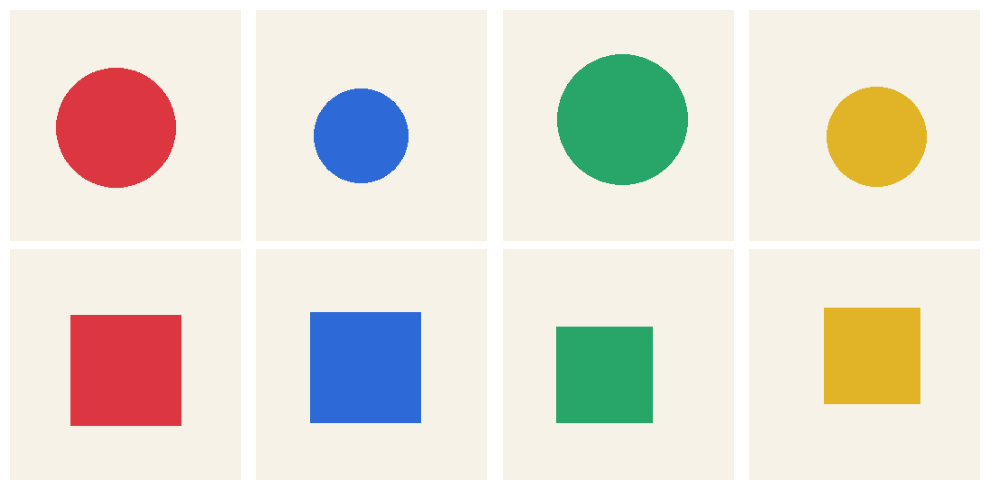

Imágenes: 64 | Metadatos: /content/datos_lora/metadata.jsonl


In [2]:
from PIL import Image,ImageDraw
import matplotlib.pyplot as plt
COLORS={"red":(220,55,65),"blue":(45,105,215),"green":(40,165,105),"yellow":(225,180,40)}
SHAPES=["circle","square","triangle","diamond"]
rows=[]
for i in range(64):
    color=list(COLORS)[i%4]
    shape=SHAPES[(i//4)%4]
    rng=random.Random(2026+i)
    cx,cy=128+rng.randint(-18,18),128+rng.randint(-18,18)
    r=rng.randint(50,78)
    img=Image.new("RGB",(256,256),(246,242,231))
    draw=ImageDraw.Draw(img)
    if shape=="circle":draw.ellipse((cx-r,cy-r,cx+r,cy+r),fill=COLORS[color])
    elif shape=="square":draw.rectangle((cx-r,cy-r,cx+r,cy+r),fill=COLORS[color])
    elif shape=="triangle":draw.polygon([(cx,cy-r),(cx-r,cy+r),(cx+r,cy+r)],fill=COLORS[color])
    else:draw.polygon([(cx,cy-r),(cx+r,cy),(cx,cy+r),(cx-r,cy)],fill=COLORS[color])
    name=f"{i:04d}.png"
    img.save(DATA/name)
    rows.append({"file_name":name,"text":f"minimal flat illustration of a {color} {shape} on a cream background"})
with (DATA/"metadata.jsonl").open("w",encoding="utf-8") as f:
    for row in rows:f.write(json.dumps(row)+"\n")
fig,axes=plt.subplots(2,4,figsize=(10,5))
for ax,row in zip(axes.flat,rows[:8]):
    ax.imshow(Image.open(DATA/row["file_name"]))
    ax.axis("off")
plt.tight_layout()
plt.savefig(EV/"01_dataset.png",dpi=140)
plt.show()
print("Imágenes:",len(rows),"| Metadatos:",DATA/"metadata.jsonl")

In [3]:
def command(args,log=None):
    print("$"," ".join(map(str,args)),flush=True)
    if log:
        with open(log,"w",encoding="utf-8") as f:
            return subprocess.run(list(map(str,args)),stdout=f,stderr=subprocess.STDOUT,check=True)
    return subprocess.run(list(map(str,args)),check=True)
if GPU:
    command([sys.executable,"-m","pip","install","-q",
        "diffusers==0.35.1","transformers>=4.41,<5","accelerate>=0.31,<2",
        "datasets>=2.19,<5","peft>=0.11,<1","safetensors","tensorboard",
        "torchvision","ftfy","sentencepiece","protobuf"])
    REPO=ROOT/"diffusers_examples"
    if not (REPO/"examples"/"text_to_image"/"train_text_to_image_lora.py").exists():
        command(["git","clone","--depth","1","--branch","v0.35.1",
                 "https://github.com/huggingface/diffusers.git",str(REPO)])
    SCRIPT=REPO/"examples"/"text_to_image"/"train_text_to_image_lora.py"
    req=SCRIPT.parent/"requirements.txt"
    if req.exists():
        command([sys.executable,"-m","pip","install","-q","-r",str(req)])
    print("Script oficial:",SCRIPT,"| existe:",SCRIPT.exists())
else:
    SCRIPT=None
    print("Instalación de entrenamiento pendiente: primero activa GPU en Colab.")

$ /usr/bin/python3 -m pip install -q diffusers==0.35.1 transformers>=4.41,<5 accelerate>=0.31,<2 datasets>=2.19,<5 peft>=0.11,<1 safetensors tensorboard torchvision ftfy sentencepiece protobuf
$ /usr/bin/python3 -m pip install -q -r /content/diffusers_examples/examples/text_to_image/requirements.txt
Script oficial: /content/diffusers_examples/examples/text_to_image/train_text_to_image_lora.py | existe: True


In [4]:
%pip install --upgrade "peft>=0.17.0,<1.0" "accelerate>=0.31.0" "transformers>=4.41,<5" "diffusers==0.35.1"

  Using cached peft-0.22.0-py3-none-any.whl.metadata (15 kB)
Using cached peft-0.22.0-py3-none-any.whl (886 kB)
  Attempting uninstall: peft
    Found existing installation: peft 0.7.0
    Uninstalling peft-0.7.0:
      Successfully uninstalled peft-0.7.0


/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:52: FutureWarning: Support for Transformers < 5.6 is deprecated in PEFT and will be removed in the next release, v1.0. You have Transformers 4.57.6. Please upgrade to Transformers >= 5.6.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model_index.json:   0%|          | 0.00/584 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

vocab.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/737 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/755 [00:00<?, ?B/s]

... (7 outputs left out)

vae/diffusion_pytorch_model.bin:   0%|          | 0.00/167M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
`torch_dtype` is deprecated! Use `dtype` instead!
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.


  0%|          | 0/15 [00:00<?, ?it/s]

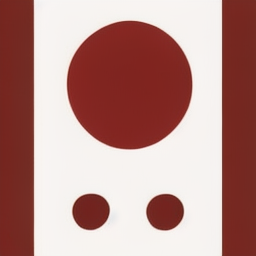

In [5]:
BASE_MODEL="segmind/tiny-sd"
PROMPT="minimal flat illustration of a red circle on a cream background"
RESOLUTION=256
MAX_STEPS=60
RANK=4
if GPU:
    from diffusers import StableDiffusionPipeline
    pipe=StableDiffusionPipeline.from_pretrained(BASE_MODEL,torch_dtype=torch.float16)
    pipe=pipe.to("cuda")
    pipe.enable_attention_slicing()
    with torch.inference_mode():
        image_before=pipe(PROMPT,num_inference_steps=15,height=256,width=256,
            generator=torch.Generator(device="cuda").manual_seed(42)).images[0]
    image_before.save(EV/"02_modelo_base.png")
    display(image_before)
    del pipe
    torch.cuda.empty_cache()
else:
    print("Prueba de generación pendiente: GPU no disponible.")

In [6]:
if GPU:
    cmd=[sys.executable,"-m","accelerate.commands.launch","--num_processes=1",
        "--mixed_precision=fp16",str(SCRIPT),
        "--pretrained_model_name_or_path",BASE_MODEL,
        "--train_data_dir",str(DATA),
        "--image_column","image","--caption_column","text",
        "--resolution",str(RESOLUTION),"--center_crop",
        "--train_batch_size","1","--gradient_accumulation_steps","1",
        "--max_train_steps",str(MAX_STEPS),
        "--learning_rate","1e-4","--rank",str(RANK),
        "--lr_scheduler","constant","--lr_warmup_steps","0",
        "--mixed_precision","fp16","--seed","42",
        "--output_dir",str(OUT),"--report_to","tensorboard",
        "--checkpointing_steps","30"]
    print("Iniciando entrenamiento real; los registros aparecerán en pantalla.")
    start=time.time()
    try:
        command(cmd)
    except subprocess.CalledProcessError as exc:
        print("ERROR EN ENTRENAMIENTO:",exc)
        print("Si es CUDA out of memory: reinicia Colab y cambia RESOLUTION a 128.")
        print("Si es acceso al modelo: revisa Hugging Face y la conexión.")
        raise
    finally:
        print("Tiempo transcurrido (min):",round((time.time()-start)/60,2))
else:
    print("ENTRENAMIENTO NO EJECUTADO: activa GPU CUDA y ejecuta desde la primera celda.")

Iniciando entrenamiento real; los registros aparecerán en pantalla.
$ /usr/bin/python3 -m accelerate.commands.launch --num_processes=1 --mixed_precision=fp16 /content/diffusers_examples/examples/text_to_image/train_text_to_image_lora.py --pretrained_model_name_or_path segmind/tiny-sd --train_data_dir /content/datos_lora --image_column image --caption_column text --resolution 256 --center_crop --train_batch_size 1 --gradient_accumulation_steps 1 --max_train_steps 60 --learning_rate 1e-4 --rank 4 --lr_scheduler constant --lr_warmup_steps 0 --mixed_precision fp16 --seed 42 --output_dir /content/resultados_lora --report_to tensorboard --checkpointing_steps 30
Tiempo transcurrido (min): 1.31


In [7]:
weights=OUT/"pytorch_lora_weights.safetensors"
TRAINED=weights.exists()
print("Adaptador encontrado:",TRAINED)
if TRAINED:
    print("Archivo:",weights,"| Tamaño MB:",round(weights.stat().st_size/1e6,2))
else:
    print("No hay adaptador: no se puede afirmar que se realizó fine-tuning.")

Adaptador encontrado: True
Archivo: /content/resultados_lora/pytorch_lora_weights.safetensors | Tamaño MB: 1.75


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/unet.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
An error occurred while trying to fetch /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae: Error no file named diffusion_pytorch_model.safetensors found in directory /root/.cache/huggingface/hub/models--segmind--tiny-sd/snapshots/cad0bd7495fa6c4bcca01b19a723dc91627fe84f/vae.
Defaulting to unsafe serialization. Pass `allow_pickle=False` to raise an error instead.
/usr/local/lib/python3.13/dist-packages/peft/import_utils.py:195: UserWarning: Found an incompatible version of torchao. Found version 0.10.0, but onl

  0%|          | 0/15 [00:00<?, ?it/s]

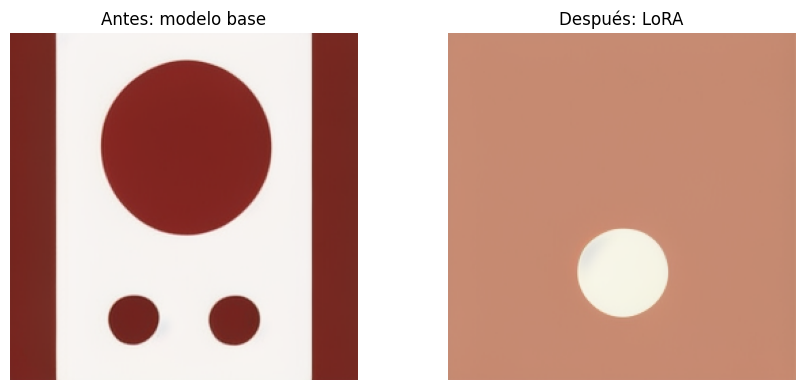

In [8]:
if GPU and TRAINED:
    from diffusers import StableDiffusionPipeline
    pipe=StableDiffusionPipeline.from_pretrained(BASE_MODEL,torch_dtype=torch.float16).to("cuda")
    pipe.enable_attention_slicing()
    pipe.load_lora_weights(str(OUT))
    with torch.inference_mode():
        after=pipe(PROMPT,num_inference_steps=15,height=256,width=256,
            generator=torch.Generator(device="cuda").manual_seed(42)).images[0]
    after.save(EV/"03_modelo_lora.png")
    before=Image.open(EV/"02_modelo_base.png")
    fig,ax=plt.subplots(1,2,figsize=(9,4))
    ax[0].imshow(before);ax[0].set_title("Antes: modelo base")
    ax[1].imshow(after);ax[1].set_title("Después: LoRA")
    for a in ax:a.axis("off")
    plt.tight_layout()
    plt.savefig(EV/"04_comparacion.png",dpi=160)
    plt.show()
    del pipe
    torch.cuda.empty_cache()
else:
    print("Comparación pendiente: requiere GPU y adaptador LoRA generado.")

In [9]:
summary={
    "gpu_disponible":bool(GPU),
    "gpu":torch.cuda.get_device_name(0) if GPU else None,
    "dataset_imagenes":len(rows),
    "modelo":BASE_MODEL,
    "resolucion":RESOLUTION,
    "pasos_solicitados":MAX_STEPS,
    "adaptador_entrenado_encontrado":bool(TRAINED),
    "evidencias":[p.name for p in sorted(EV.iterdir())]
}
(EV/"05_resumen.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")
print(json.dumps(summary,indent=2,ensure_ascii=False))
zip_path=shutil.make_archive(str(ROOT/"evidencias_lora"),"zip",EV)
print("Evidencias comprimidas:",zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Descarga el ZIP desde el explorador de archivos del entorno.")

{
  "gpu_disponible": true,
  "gpu": "Tesla T4",
  "dataset_imagenes": 64,
  "modelo": "segmind/tiny-sd",
  "resolucion": 256,
  "pasos_solicitados": 60,
  "adaptador_entrenado_encontrado": true,
  "evidencias": [
    "01_dataset.png",
    "02_modelo_base.png",
    "03_modelo_lora.png",
    "04_comparacion.png"
  ]
}
Evidencias comprimidas: /content/evidencias_lora.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>